# AIML IA
## Feature Engineering and Data Preprocessing on a Web-Scraped Dataset

**Title:** Feature Engineering and Data Preprocessing on a Web-Scraped Dataset  
**Dataset Source:** Books to Scrape — https://books.toscrape.com/  
**Tools:** Python, Requests, BeautifulSoup, Pandas, NumPy, Matplotlib, Seaborn, Scikit-Learn  



**Name:** Hrishikesh Nandkishor Koshti

**PRN:** 202401040054

**Division:** A

**Roll No.:** A1-17

**Subject:** Artificial Intelligence and Machine Learning

# SECTION 1: Project Introduction

## 1.1 Problem Statement

Real-world data collected from websites is rarely ready for direct analysis or machine learning. It may contain inconsistent text, missing values, duplicate records, incorrect data types, and extreme values.

In this project, book information is collected from the publicly accessible **Books to Scrape** website. The scraped data is then explored, realistic data-quality problems are introduced, cleaned, transformed, and converted into useful machine-learning features.

The final processed dataset is used to train a simple classification model for predicting a book's **rating class** from other available book attributes.

## 1.2 Objectives

1. Collect at least 200 book records using web scraping.
2. Store the scraped information in a Pandas DataFrame and CSV file.
3. Perform Exploratory Data Analysis (EDA).
4. Identify and simulate common real-world data-quality problems.
5. Handle missing values, duplicates, inconsistent strings, and data types.
6. Detect and treat outliers using the IQR method.
7. Perform feature engineering such as label encoding and derived features.
8. Apply Standardization and Min-Max Normalization.
9. Visualize important characteristics of the dataset.
10. Build and evaluate a Random Forest classification model.
11. Save the final cleaned and feature-engineered dataset.

## 1.3 Importance of Feature Engineering

Feature engineering converts raw data into meaningful variables that machine-learning algorithms can use effectively.

For example:
- A price such as `£51.77` is converted into a numerical value.
- Rating words such as `Four` are converted into `4`.
- Availability text is converted into an `Availability_Flag`.
- Price is converted into categories such as `Low`, `Medium`, and `High`.
- A `Premium_Book` feature identifies relatively expensive books.

Good features can improve interpretability and model performance.

## 1.4 Importance of Data Preprocessing

Data preprocessing improves the quality and consistency of raw data before machine learning.

Important preprocessing operations include:
- Missing-value treatment
- Duplicate removal
- Data-type conversion
- String cleaning
- Outlier treatment
- Encoding categorical values
- Feature scaling

Therefore, preprocessing is an essential stage of a reliable machine-learning workflow.

# SECTION 2: Web Scraping

In this section, the dataset is created from the Books to Scrape website.

The website is designed specifically for practicing web scraping. I use:
- **Requests** to download HTML pages.
- **BeautifulSoup** to parse HTML.
- **Pandas** to store the collected records.
- **NumPy** for numerical operations.

In [ ]:
# Import all major libraries required for the project.

import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn libraries used later for preprocessing and machine learning.
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Utility libraries.
import time
import re
import warnings

warnings.filterwarnings("ignore")

# Set a professional plotting style.
sns.set_theme(style="whitegrid")

print("All required libraries imported successfully.")

All required libraries imported successfully.


### Explanation

The libraries are imported at the beginning so that the notebook can use one consistent Python environment throughout the project. Requests and BeautifulSoup are used for web scraping, Pandas and NumPy for data processing, Matplotlib and Seaborn for visualization, and Scikit-Learn for preprocessing and machine learning.

In [ ]:
# Define the website and HTTP headers.
# The User-Agent makes the request look like a normal browser request.

BASE_URL = "https://books.toscrape.com/"
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
                  "AppleWebKit/537.36 (KHTML, like Gecko) "
                  "Chrome/120.0 Safari/537.36"
}

# Test that the website is reachable.
response = requests.get(BASE_URL, headers=HEADERS, timeout=20)

print("HTTP Status Code:", response.status_code)
print("Page downloaded successfully:", response.ok)

HTTP Status Code: 200
Page downloaded successfully: True


### Explanation

`requests.get()` sends an HTTP GET request to the website. A status code of **200** normally means that the request was successful. The HTML response is then available through `response.text`.

In [ ]:
# Parse the downloaded HTML using BeautifulSoup.

soup = BeautifulSoup(response.text, "html.parser")

# Display the title of the webpage as a simple parsing check.
print("Website title:", soup.title.get_text(strip=True))

Website title: All products | Books to Scrape - Sandbox


### Explanation

BeautifulSoup converts the raw HTML into a searchable structure. This allows us to locate elements such as book titles, prices, ratings, and availability using HTML tags and CSS classes.

In [ ]:
# Function to convert a relative book URL into an absolute URL.
def make_absolute_url(relative_url):
    return requests.compat.urljoin(BASE_URL, relative_url)

# Function to convert rating words into numbers.
# This is also useful later during feature engineering.
rating_map = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

# Scrape at least 200 books.
# Each listing page contains 20 books, so 10 pages provide 200 records.
target_records = 200
records = []

for page_no in range(1, 11):
    page_url = BASE_URL if page_no == 1 else f"{BASE_URL}catalogue/page-{page_no}.html"

    page_response = requests.get(page_url, headers=HEADERS, timeout=20)
    page_response.raise_for_status()
    page_soup = BeautifulSoup(page_response.text, "html.parser")

    books = page_soup.select("article.product_pod")

    for book in books:
        # Extract title.
        title_tag = book.select_one("h3 a")
        title = title_tag.get("title", "").strip() if title_tag else ""

        # Extract price text.
        price_tag = book.select_one("p.price_color")
        price = price_tag.get_text(strip=True) if price_tag else ""

        # Extract rating class such as "star-rating Four".
        rating_tag = book.select_one("p.star-rating")
        rating_word = ""
        if rating_tag:
            rating_classes = rating_tag.get("class", [])
            rating_word = next(
                (item for item in rating_classes if item in rating_map),
                ""
            )

        # Extract availability text.
        availability_tag = book.select_one("p.instock.availability")
        availability = (
            availability_tag.get_text(" ", strip=True)
            if availability_tag else ""
        )

        # Extract the book detail page URL.
        detail_url = ""
        if title_tag and title_tag.get("href"):
            detail_url = make_absolute_url(title_tag["href"])

        # Category is available on the individual book page.
        category = ""
        if detail_url:
            try:
                detail_response = requests.get(
                    detail_url, headers=HEADERS, timeout=20
                )
                detail_response.raise_for_status()
                detail_soup = BeautifulSoup(
                    detail_response.text, "html.parser"
                )

                breadcrumb_links = detail_soup.select("ul.breadcrumb li a")
                # On Books to Scrape the category is the second link
                # after Home in the breadcrumb.
                if len(breadcrumb_links) >= 2:
                    category = breadcrumb_links[-1].get_text(strip=True)

                # Small delay to avoid sending requests too quickly.
                time.sleep(0.05)
            except requests.RequestException:
                category = "Unknown"

        records.append({
            "Book_Title": title,
            "Price": price,
            "Rating": rating_word,
            "Availability_Status": availability,
            "Category": category,
            "Book_URL": detail_url
        })

        if len(records) >= target_records:
            break

    print(f"Page {page_no}: collected {len(records)} records")

    if len(records) >= target_records:
        break

    # Small delay between catalogue pages.
    time.sleep(0.2)

print("\nTotal records collected:", len(records))

Page 1: collected 20 records
Page 2: collected 40 records
Page 3: collected 60 records
Page 4: collected 80 records
Page 5: collected 100 records
Page 6: collected 120 records
Page 7: collected 140 records
Page 8: collected 160 records
Page 9: collected 180 records
Page 10: collected 200 records

Total records collected: 200


### Explanation

The scraper visits the catalogue pages one by one. For each book, it extracts:
- Book title
- Price
- Rating
- Availability status
- Category
- Book detail URL

The category is obtained from the individual book page because it is not directly available in the main product card. The loop stops after at least 200 records have been collected.

In [ ]:
# Create a Pandas DataFrame from the scraped records.

raw_df = pd.DataFrame(records)

# Keep exactly the required project fields in the main dataset.
raw_df = raw_df[
    ["Book_Title", "Price", "Rating", "Availability_Status", "Category"]
].copy()

# Save the raw web-scraped dataset.
raw_df.to_csv("raw_books_scraped.csv", index=False)

print("Raw dataset saved as: raw_books_scraped.csv")
print("Dataset shape:", raw_df.shape)

Raw dataset saved as: raw_books_scraped.csv
Dataset shape: (200, 5)


### Explanation

The list of dictionaries is converted into a Pandas DataFrame. The raw dataset is saved as `raw_books_scraped.csv`. Keeping a raw copy is useful because it preserves the original scraped information before preprocessing.

In [ ]:
# Display the first few scraped records.

display(raw_df.head())

,Book_Title,Price,Rating,Availability_Status,Category
0,A Light in the Attic,Â£51.77,Three,In stock,Poetry
1,Tipping the Velvet,Â£53.74,One,In stock,Historical Fiction
2,Soumission,Â£50.10,One,In stock,Fiction
3,Sharp Objects,Â£47.82,Four,In stock,Mystery
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,History


### Explanation

`head()` displays the first five records and confirms that the scraper produced a structured dataset with the required fields.

# SECTION 3: Exploratory Data Analysis (EDA)

EDA is performed before cleaning so that the structure and quality of the raw data can be understood.

We examine:
- Dataset dimensions
- Column data types
- Missing values
- Duplicate rows
- Statistical information

In [ ]:
# Display the first five records.
display(raw_df.head())

# Display the last five records.
display(raw_df.tail())

# Display the shape as (rows, columns).
print("Dataset Shape:", raw_df.shape)

,Book_Title,Price,Rating,Availability_Status,Category
0,A Light in the Attic,Â£51.77,Three,In stock,Poetry
1,Tipping the Velvet,Â£53.74,One,In stock,Historical Fiction
2,Soumission,Â£50.10,One,In stock,Fiction
3,Sharp Objects,Â£47.82,Four,In stock,Mystery
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock,History


,Book_Title,Price,Rating,Availability_Status,Category
195,Eureka Trivia 6.0,Â£54.59,Four,In stock,Unknown
196,Drive: The Surprising Truth About What Motivat...,Â£34.95,Four,In stock,Unknown
197,Done Rubbed Out (Reightman & Bailey #1),Â£37.72,Five,In stock,Unknown
198,Doing It Over (Most Likely To #1),Â£35.61,Three,In stock,Unknown
199,Deliciously Ella Every Day: Quick and Easy Rec...,Â£42.16,Three,In stock,Unknown


Dataset Shape: (200, 5)


### Explanation

The dataset shape tells us how many observations and variables are available. `head()` and `tail()` provide a quick visual inspection of the beginning and end of the dataset.

In [ ]:
# Display information about columns, non-null values, and data types.

raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Book_Title           200 non-null    object
 1   Price                200 non-null    object
 2   Rating               200 non-null    object
 3   Availability_Status  200 non-null    object
 4   Category             200 non-null    object
dtypes: object(5)
memory usage: 7.9+ KB


### Explanation

`info()` shows the number of non-null values and the current data type of every column. At this stage, price and availability are stored mainly as strings because they were extracted directly from HTML.

In [ ]:
# Display the data type of every column.

print(raw_df.dtypes)

Book_Title             object
Price                  object
Rating                 object
Availability_Status    object
Category               object
dtype: object


### Explanation

Data types are important because machine-learning algorithms require numerical features in numerical form. Text representations of prices and ratings must therefore be transformed later.

In [ ]:
# Count missing values in every column.

null_counts = raw_df.isnull().sum()
display(null_counts.to_frame("Null_Count"))

,Null_Count
Book_Title,0
Price,0
Rating,0
Availability_Status,0
Category,0


### Explanation

`isnull().sum()` counts missing values column by column. Missing values can cause incorrect calculations and may lead to errors in machine-learning algorithms if they are not handled.

In [ ]:
# Count completely duplicated rows.

duplicate_count = raw_df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


### Explanation

Duplicate rows represent repeated observations. If duplicates are not removed, they can bias statistical analysis and may give some observations more influence during model training.

In [ ]:
# Statistical summary of numeric columns is limited at this stage
# because the raw price and rating are text values.
display(raw_df.describe(include="all").T)

,count,unique,top,freq
Book_Title,200,200,A Light in the Attic,1
Price,200,196,Â£44.18,2
Rating,200,5,One,49
Availability_Status,200,1,In stock,200
Category,200,14,Unknown,180


### Explanation

`describe(include="all")` provides a general summary for both numerical and categorical columns. Numeric summaries such as mean and standard deviation become more meaningful after data-type conversion.

# SECTION 4: Dataset Quality Issues

Real-world scraped data can contain quality problems. To demonstrate the preprocessing workflow, controlled issues are introduced into a copy of the raw dataset.

We will simulate:
1. Missing values
2. Duplicate rows
3. Outliers

These changes are made only to the working copy, so the original raw scraped dataset remains preserved.

In [ ]:
# Create a fresh copy of the raw scraped dataset.
problem_df = raw_df.copy()

# Set a fixed random seed so results are reproducible.
np.random.seed(42)

# Select 12 random rows.
missing_indices = np.random.choice(
    problem_df.index,
    size=12,
    replace=False
)

# Introduce missing prices.
problem_df.loc[missing_indices[:4], "Price"] = np.nan

# Introduce missing ratings.
problem_df.loc[missing_indices[4:8], "Rating"] = np.nan

# Introduce missing categories.
problem_df.loc[missing_indices[8:], "Category"] = np.nan


# Select 5 rows and duplicate them.
duplicate_rows = problem_df.sample(
    5,
    random_state=42
)

problem_df = pd.concat(
    [problem_df, duplicate_rows],
    ignore_index=True
)

# Extract the numerical part of the price.
# This works even if the currency symbol is £, Â£,
# or another non-numeric character.
problem_df["Price_Numeric_Temp"] = (
    problem_df["Price"]
    .astype("string")
    .str.extract(r"([0-9]+(?:\.[0-9]+)?)", expand=False)
)

# Convert extracted values to numbers.
problem_df["Price_Numeric_Temp"] = pd.to_numeric(
    problem_df["Price_Numeric_Temp"],
    errors="coerce"
)

# Find rows that contain valid prices.
valid_price_indices = problem_df[
    problem_df["Price_Numeric_Temp"].notna()
].index[:5]

# Multiply selected prices by 5 to create artificial
# extreme values for the outlier demonstration.
problem_df.loc[
    valid_price_indices,
    "Price_Numeric_Temp"
] *= 5


# Display the result.
print("Problematic dataset shape:", problem_df.shape)

print("\nMissing values:")
display(problem_df.isnull().sum().to_frame("Count"))

print(
    "\nValid numeric prices:",
    problem_df["Price_Numeric_Temp"].notna().sum()
)

print(
    "Duplicate rows:",
    problem_df.duplicated().sum()
)

Problematic dataset shape: (205, 6)

Missing values:


,Count
Book_Title,0
Price,8
Rating,5
Availability_Status,0
Category,4
Price_Numeric_Temp,8



Valid numeric prices: 197
Duplicate rows: 5


### Explanation

The controlled issues imitate common problems found in real-world datasets.

- **Missing values:** can prevent calculations and model training.
- **Duplicates:** can bias distributions and model learning.
- **Outliers:** can strongly affect mean, variance, scaling, and some machine-learning algorithms.

A fixed random seed makes the experiment reproducible.

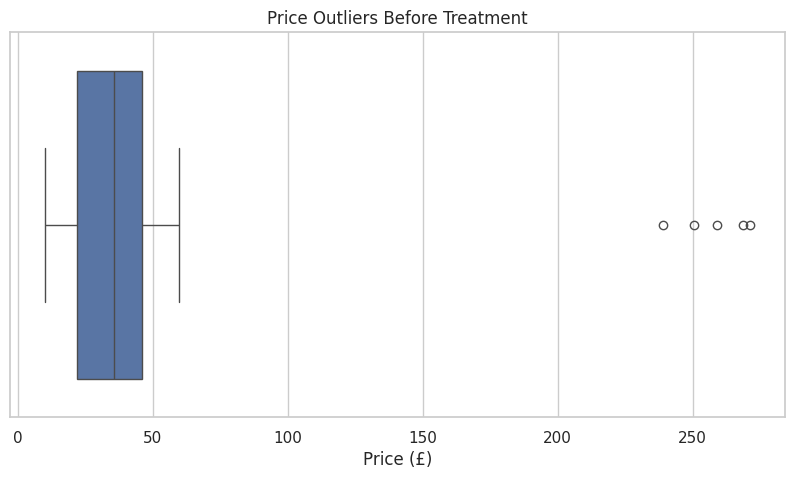

In [ ]:
# Remove missing values before plotting.
price_data = problem_df[
    "Price_Numeric_Temp"
].dropna()

# Convert to NumPy array for plotting compatibility.
price_data = price_data.to_numpy(dtype=float)

# Create the boxplot.
plt.figure(figsize=(10, 5))

sns.boxplot(x=price_data)

# Add title and labels.
plt.title("Price Outliers Before Treatment")
plt.xlabel("Price (£)")

# Display the plot.
plt.show()

### Explanation

A boxplot provides a visual method for identifying potential outliers. Points beyond the whiskers are commonly treated as possible outliers. In this assignment, the extreme values were intentionally created for demonstrating the IQR method.

# SECTION 5: Data Cleaning

The following cleaning operations are performed:

1. Convert price from text to numerical data.
2. Clean strings and whitespace.
3. Handle missing values using mean, median, and mode where appropriate.
4. Remove duplicate records.
5. Verify the cleaned dataset.

### Missing-value strategy

- **Mean:** suitable for numerical data when extreme values are not dominant.
- **Median:** more robust for numerical data when outliers may exist.
- **Mode:** suitable for categorical values such as rating and category.

For the final dataset, median is used for price and mode is used for categorical variables.

In [ ]:
# Create a fresh cleaned dataset from the corrected problematic dataset.

clean_df = problem_df.drop(
    columns=["Price_Numeric_Temp"]
).copy()

# ---------------------------------------------------------
# Clean string columns
# ---------------------------------------------------------

string_columns = [
    "Book_Title",
    "Price",
    "Rating",
    "Availability_Status",
    "Category"
]

for column in string_columns:
    # Convert values to string type.
    clean_df[column] = clean_df[column].astype("string")

    # Remove unnecessary spaces.
    clean_df[column] = clean_df[column].str.strip()

    # Convert empty strings to missing values.
    clean_df[column] = clean_df[column].replace(
        {"": pd.NA, "nan": pd.NA}
    )


# ---------------------------------------------------------
# Convert Price into numerical form
# ---------------------------------------------------------

# Extract only the numerical portion from the price.
# Example: £51.77 → 51.77
clean_df["Price_Numeric"] = (
    clean_df["Price"]
    .str.extract(
        r"([0-9]+(?:\.[0-9]+)?)",
        expand=False
    )
)

# Convert the extracted value to numeric.
clean_df["Price_Numeric"] = pd.to_numeric(
    clean_df["Price_Numeric"],
    errors="coerce"
)

# Check the result.
print("Price data type:", clean_df["Price_Numeric"].dtype)
print(
    "Valid prices:",
    clean_df["Price_Numeric"].notna().sum()
)
print(
    "Missing prices:",
    clean_df["Price_Numeric"].isna().sum()
)

# Display sample values.
display(
    clean_df[
        ["Price", "Price_Numeric"]
    ].head(10)
)

Price data type: Float64
Valid prices: 197
Missing prices: 8


,Price,Price_Numeric
0,Â£51.77,51.77
1,Â£53.74,53.74
2,Â£50.10,50.1
3,Â£47.82,47.82
4,Â£54.23,54.23
5,Â£22.65,22.65
6,Â£33.34,33.34
7,Â£17.93,17.93
8,Â£22.60,22.6
9,Â£52.15,52.15


### Explanation

The price contains the currency symbol `£`, so it cannot be used directly in numerical calculations. It is cleaned and converted to a floating-point number. String columns are also stripped of unnecessary whitespace.

In [ ]:
# Demonstrate Mean, Median, and Mode imputation before selecting
# the final strategy.

price_mean = clean_df["Price_Numeric"].mean()
price_median = clean_df["Price_Numeric"].median()
rating_mode = clean_df["Rating"].mode()[0]
category_mode = clean_df["Category"].mode()[0]

print("Price Mean:", round(price_mean, 2))
print("Price Median:", round(price_median, 2))
print("Rating Mode:", rating_mode)
print("Category Mode:", category_mode)

# Apply the final imputation strategy:
# - Median for numerical price because it is less sensitive to outliers.
# - Mode for categorical rating and category.
clean_df["Price_Numeric"] = clean_df["Price_Numeric"].fillna(price_median)
clean_df["Rating"] = clean_df["Rating"].fillna(rating_mode)
clean_df["Category"] = clean_df["Category"].fillna(category_mode)

# Availability and title are also filled with their modes for robustness.
clean_df["Availability_Status"] = clean_df["Availability_Status"].fillna(
    clean_df["Availability_Status"].mode()[0]
)
clean_df["Book_Title"] = clean_df["Book_Title"].fillna("Unknown Book")

print("\nMissing values after imputation:")
display(clean_df.isnull().sum().to_frame("Null_Count"))

Price Mean: 34.84
Price Median: 35.67
Rating Mode: One
Category Mode: Unknown

Missing values after imputation:


,Null_Count
Book_Title,0
Price,8
Rating,0
Availability_Status,0
Category,0
Price_Numeric,0


### Explanation

Three standard imputation ideas are demonstrated. The final implementation uses the **median** for price because price may contain extreme observations, while **mode** is used for categorical variables. This prevents missing values from remaining in the final working dataset.

In [ ]:
# Remove duplicate records after missing-value treatment.

before_duplicates = len(clean_df)

clean_df = clean_df.drop_duplicates().reset_index(drop=True)

after_duplicates = len(clean_df)

print("Rows before duplicate removal:", before_duplicates)
print("Rows after duplicate removal:", after_duplicates)
print("Duplicates remaining:", clean_df.duplicated().sum())

Rows before duplicate removal: 205
Rows after duplicate removal: 200
Duplicates remaining: 0


### Explanation

`drop_duplicates()` removes repeated observations. The before-and-after counts demonstrate how many duplicate rows were removed.

In [ ]:
# Verify the cleaned dataset.

print("Final cleaned shape at this stage:", clean_df.shape)
print("\nMissing values:")
display(clean_df.isnull().sum().to_frame("Null_Count"))

print("\nDuplicate rows:", clean_df.duplicated().sum())

print("\nData types:")
display(clean_df.dtypes)

Final cleaned shape at this stage: (200, 6)

Missing values:


,Null_Count
Book_Title,0
Price,4
Rating,0
Availability_Status,0
Category,0
Price_Numeric,0



Duplicate rows: 0

Data types:


,0
Book_Title,string[python]
Price,string[python]
Rating,string[python]
Availability_Status,string[python]
Category,string[python]
Price_Numeric,Float64


### Explanation

The verification step confirms that the important data-quality issues have been addressed. A good preprocessing pipeline always includes validation after cleaning rather than assuming the transformations worked correctly.

# SECTION 6: Feature Engineering

Feature engineering creates variables that are more useful for analysis and machine learning.

## 6.1 Label Encoding of Rating

The website represents ratings as words:

- One → 1
- Two → 2
- Three → 3
- Four → 4
- Five → 5

This conversion creates a numerical target suitable for classification.

## 6.2 New Features

### Price Category
Groups books into:
- Low
- Medium
- High

### Availability Flag
Indicates whether the book is currently available.

### Premium Book Indicator
Marks books whose price is above the dataset median.

In [ ]:
# Convert rating words to numerical values.

clean_df["Rating_Numeric"] = clean_df["Rating"].map(rating_map)

# Create price categories using quantile-based thresholds.
price_q33 = clean_df["Price_Numeric"].quantile(0.33)
price_q66 = clean_df["Price_Numeric"].quantile(0.66)

clean_df["Price_Category"] = pd.cut(
    clean_df["Price_Numeric"],
    bins=[-np.inf, price_q33, price_q66, np.inf],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

# Create an availability flag.
clean_df["Availability_Flag"] = (
    clean_df["Availability_Status"]
    .str.contains("In stock", case=False, na=False)
    .astype(int)
)

# Create the premium-book indicator.
price_median_for_feature = clean_df["Price_Numeric"].median()

clean_df["Premium_Book"] = (
    clean_df["Price_Numeric"] > price_median_for_feature
).astype(int)

# Display the newly created features.
display(
    clean_df[
        [
            "Book_Title",
            "Rating",
            "Rating_Numeric",
            "Price_Numeric",
            "Price_Category",
            "Availability_Flag",
            "Premium_Book"
        ]
    ].head(10)
)

,Book_Title,Rating,Rating_Numeric,Price_Numeric,Price_Category,Availability_Flag,Premium_Book
0,A Light in the Attic,Three,3,51.77,High,1,1
1,Tipping the Velvet,One,1,53.74,High,1,1
2,Soumission,One,1,50.1,High,1,1
3,Sharp Objects,Four,4,47.82,High,1,1
4,Sapiens: A Brief History of Humankind,Five,5,54.23,High,1,1
5,The Requiem Red,One,1,22.65,Low,1,0
6,The Dirty Little Secrets of Getting Your Dream...,Four,4,33.34,Medium,1,0
7,The Coming Woman: A Novel Based on the Life of...,Three,3,17.93,Low,1,0
8,The Boys in the Boat: Nine Americans and Their...,Four,4,22.6,Low,1,0
9,The Black Maria,One,1,52.15,High,1,1


### Explanation

The raw rating is transformed into an ordered numerical value. New features summarize information in a machine-learning-friendly way. Binary indicators contain `0` or `1`, while `Price_Category` converts continuous price into interpretable groups.

In [ ]:
# Show the distribution of the engineered categorical features.

print("Price Category counts:")
display(clean_df["Price_Category"].value_counts())

print("Availability Flag counts:")
display(clean_df["Availability_Flag"].value_counts())

print("Premium Book counts:")
display(clean_df["Premium_Book"].value_counts())

Price Category counts:


,count
Price_Category,
High,68
Low,66
Medium,66


Availability Flag counts:


,count
Availability_Flag,
1,200


Premium Book counts:


,count
Premium_Book,
0,102
1,98


### Explanation

Frequency counts help verify whether the engineered categories were created correctly and whether both classes of the binary variables are represented.

# SECTION 7: Outlier Detection and Treatment

Outliers are unusually high or low observations.

The **Interquartile Range (IQR)** method is used:

- Q1 = 25th percentile
- Q3 = 75th percentile
- IQR = Q3 − Q1
- Lower Bound = Q1 − 1.5 × IQR
- Upper Bound = Q3 + 1.5 × IQR

Values outside these bounds are treated as potential outliers.

For this project, price outliers are handled using **IQR capping (winsorization)**. Capping is chosen instead of deleting rows so that valid book records are retained.

In [ ]:
# Function to calculate IQR bounds and identify outliers.

def iqr_outlier_info(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (series < lower_bound) | (series > upper_bound)

    return q1, q3, iqr, lower_bound, upper_bound, outlier_mask

q1, q3, iqr, lower_bound, upper_bound, outlier_mask = (
    iqr_outlier_info(clean_df["Price_Numeric"])
)

print("Q1:", round(q1, 2))
print("Q3:", round(q3, 2))
print("IQR:", round(iqr, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Number of price outliers before treatment:", int(outlier_mask.sum()))

Q1: 22.15
Q3: 45.72
IQR: 23.57
Lower Bound: -13.2
Upper Bound: 81.07
Number of price outliers before treatment: 0


### Explanation

The IQR calculation gives objective boundaries for detecting extreme prices. The number of observations outside these boundaries is reported before treatment.

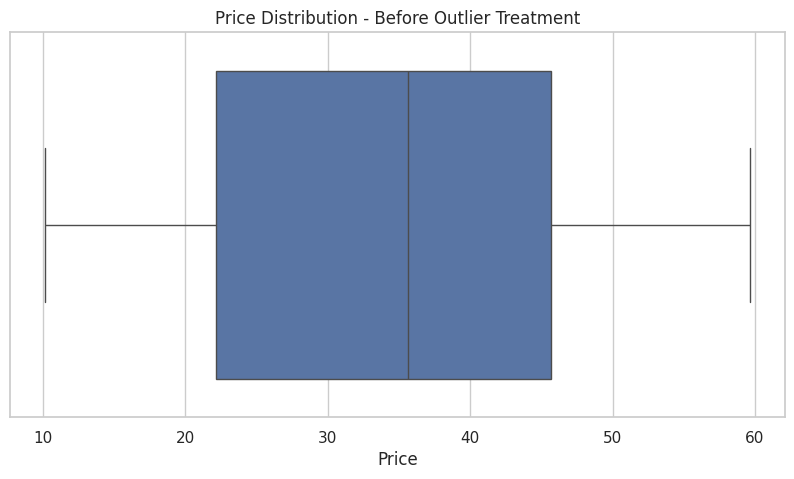

In [ ]:
# Boxplot before outlier treatment.

plt.figure(figsize=(10, 5))
sns.boxplot(x=clean_df["Price_Numeric"])
plt.title("Price Distribution - Before Outlier Treatment")
plt.xlabel("Price")
plt.show()

### Explanation

The boxplot makes the possible extreme price values visually identifiable. This provides a graphical complement to the numerical IQR calculation.

In [ ]:
# Apply IQR capping instead of deleting the observations.

clean_df["Price_Numeric"] = clean_df["Price_Numeric"].clip(
    lower=lower_bound,
    upper=upper_bound
)

# Recalculate outliers after treatment.
_, _, _, new_lower, new_upper, new_outlier_mask = (
    iqr_outlier_info(clean_df["Price_Numeric"])
)

print("Number of price outliers after treatment:", int(new_outlier_mask.sum()))

Number of price outliers after treatment: 0


### Explanation

`clip()` caps values below the lower boundary and above the upper boundary. This reduces the influence of extreme values while preserving the corresponding book records.

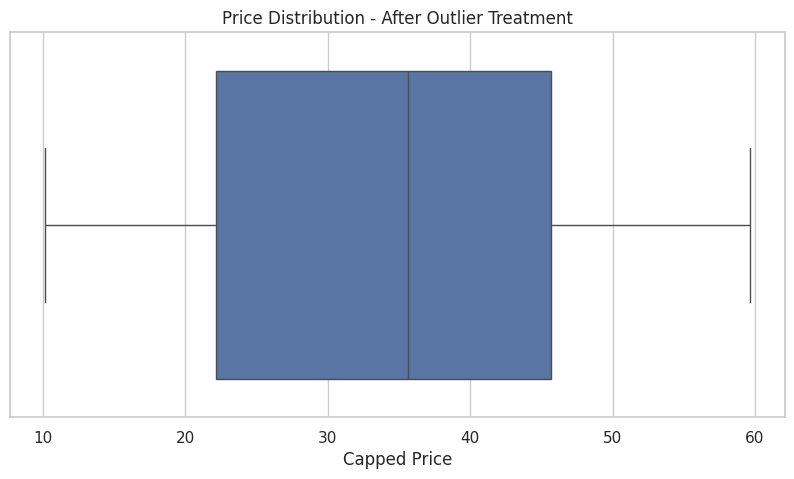

In [ ]:
# Boxplot after outlier treatment.

plt.figure(figsize=(10, 5))
sns.boxplot(x=clean_df["Price_Numeric"])
plt.title("Price Distribution - After Outlier Treatment")
plt.xlabel("Capped Price")
plt.show()

### Explanation

The second boxplot shows the distribution after IQR capping. The extreme influence of the artificially introduced outliers has been reduced.

# SECTION 8: Statistical Analysis

Statistical measures summarize the distribution of numerical data.

- **Mean:** arithmetic average.
- **Median:** middle value after sorting.
- **Mode:** most frequently occurring value.
- **Variance:** measures squared spread around the mean.
- **Standard Deviation:** square root of variance; indicates typical spread.
- **Minimum:** smallest observation.
- **Maximum:** largest observation.
- **Range:** maximum − minimum.

These statistics help understand central tendency and variability before modeling.

In [ ]:
# Calculate descriptive statistics for the cleaned price feature.

price_series = clean_df["Price_Numeric"]

statistics = {
    "Mean": price_series.mean(),
    "Median": price_series.median(),
    "Mode": price_series.mode().iloc[0],
    "Variance": price_series.var(),
    "Standard Deviation": price_series.std(),
    "Minimum": price_series.min(),
    "Maximum": price_series.max(),
    "Range": price_series.max() - price_series.min()
}

statistics_df = pd.DataFrame(
    {"Statistic": statistics.keys(), "Value": statistics.values()}
)

statistics_df["Value"] = statistics_df["Value"].round(4)

display(statistics_df)

,Statistic,Value
0,Mean,34.9198
1,Median,35.6700
2,Mode,35.6700
3,Variance,193.5511
4,Standard Deviation,13.9123
5,Minimum,10.1600
6,Maximum,59.6400
7,Range,49.4800


### Explanation

The table provides a compact statistical profile of book prices. Mean and median describe central tendency, while variance and standard deviation describe spread. Minimum, maximum, and range show the overall extent of the observed values.

# SECTION 9: Feature Scaling

Machine-learning algorithms may perform better when numerical features are placed on comparable scales.

## 9.1 Standardization

Standardization transforms a feature approximately to:

**z = (x − mean) / standard deviation**

The resulting feature has a mean close to 0 and a standard deviation close to 1.

## 9.2 Min-Max Normalization

Min-Max scaling transforms values to a fixed interval, normally [0, 1]:

**x' = (x − min) / (max − min)**

Both techniques are demonstrated for the numerical price feature.

In [ ]:
# Create copies so that the original cleaned price remains available.

scaling_data = clean_df[["Price_Numeric"]].copy()

# Standardization.
standard_scaler = StandardScaler()
scaling_data["Price_Standardized"] = standard_scaler.fit_transform(
    scaling_data[["Price_Numeric"]]
)

# Min-Max normalization.
minmax_scaler = MinMaxScaler()
scaling_data["Price_MinMax"] = minmax_scaler.fit_transform(
    scaling_data[["Price_Numeric"]]
)

# Compare original and transformed values.
display(scaling_data.head(10).round(4))

,Price_Numeric,Price_Standardized,Price_MinMax
0,51.77,1.2142,0.8409
1,53.74,1.3562,0.8808
2,50.1,1.0939,0.8072
3,47.82,0.9296,0.7611
4,54.23,1.3915,0.8907
5,22.65,-0.8842,0.2524
6,33.34,-0.1138,0.4685
7,17.93,-1.2243,0.1570
8,22.6,-0.8878,0.2514
9,52.15,1.2416,0.8486


### Explanation

The table compares the original price with its standardized and Min-Max transformed versions. Standardized values are centered around zero, while Min-Max values are compressed into the 0-to-1 interval.

In [ ]:
# Verify the approximate properties of both scaling techniques.

print("Standardized mean:", round(
    scaling_data["Price_Standardized"].mean(), 6
))
print("Standardized standard deviation:", round(
    scaling_data["Price_Standardized"].std(), 6
))

print("Min-Max minimum:", round(
    scaling_data["Price_MinMax"].min(), 6
))
print("Min-Max maximum:", round(
    scaling_data["Price_MinMax"].max(), 6
))

Standardized mean: -0.0
Standardized standard deviation: 1.002509
Min-Max minimum: 0.0
Min-Max maximum: 1.0


### Explanation

Standardization should produce a mean close to zero and standard deviation close to one. Min-Max scaling should produce a minimum close to zero and maximum close to one. Small numerical differences may occur due to sample standard deviation conventions.

# SECTION 10: Data Visualization

Visualization makes patterns and relationships easier to understand.

The following professional plots are generated:
1. Histogram
2. Boxplot
3. Count Plot
4. Correlation Heatmap
5. Scatter Plot
6. Bar Chart

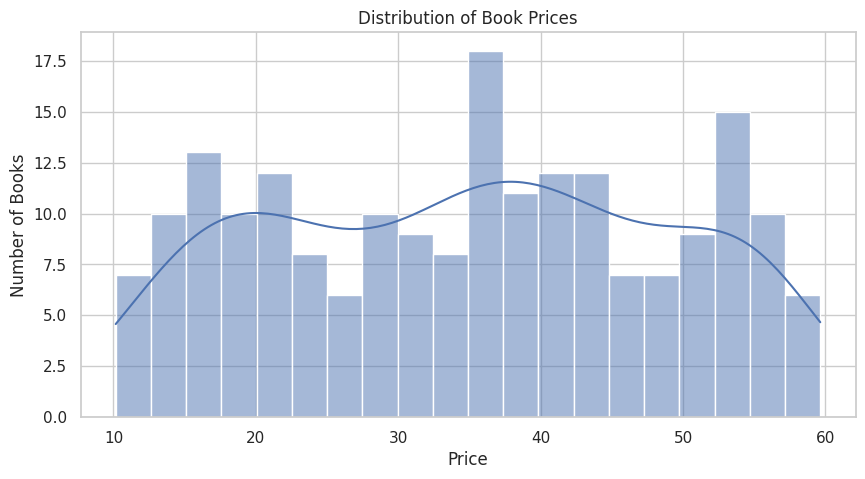

In [ ]:
# 1. Histogram of book prices.

plt.figure(figsize=(10, 5))
sns.histplot(clean_df["Price_Numeric"], bins=20, kde=True)
plt.title("Distribution of Book Prices")
plt.xlabel("Price")
plt.ylabel("Number of Books")
plt.show()

### Explanation

The histogram shows how book prices are distributed across the dataset. The KDE curve provides an approximate view of the distribution shape.

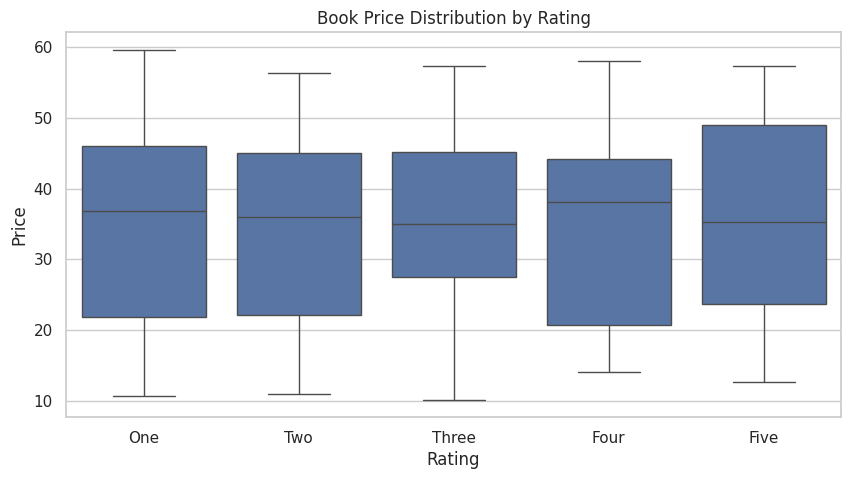

In [ ]:
# 2. Boxplot of book prices by rating.

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=clean_df,
    x="Rating",
    y="Price_Numeric",
    order=["One", "Two", "Three", "Four", "Five"]
)
plt.title("Book Price Distribution by Rating")
plt.xlabel("Rating")
plt.ylabel("Price")
plt.show()

### Explanation

This boxplot compares the price distribution across rating classes. It helps identify differences in central tendency, spread, and potential extreme values between rating groups.

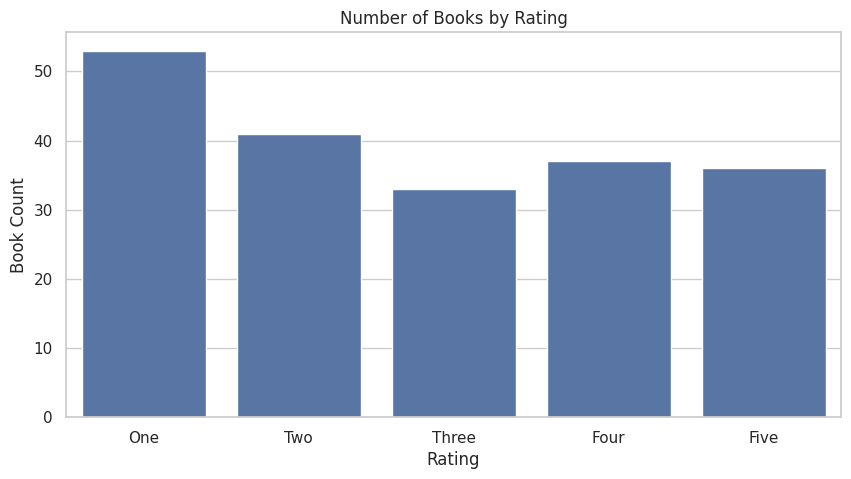

In [ ]:
# 3. Count plot of rating classes.

plt.figure(figsize=(10, 5))
sns.countplot(
    data=clean_df,
    x="Rating",
    order=["One", "Two", "Three", "Four", "Five"]
)
plt.title("Number of Books by Rating")
plt.xlabel("Rating")
plt.ylabel("Book Count")
plt.show()

### Explanation

The count plot displays the number of books in each rating class. It helps identify whether the target classes are balanced or imbalanced.

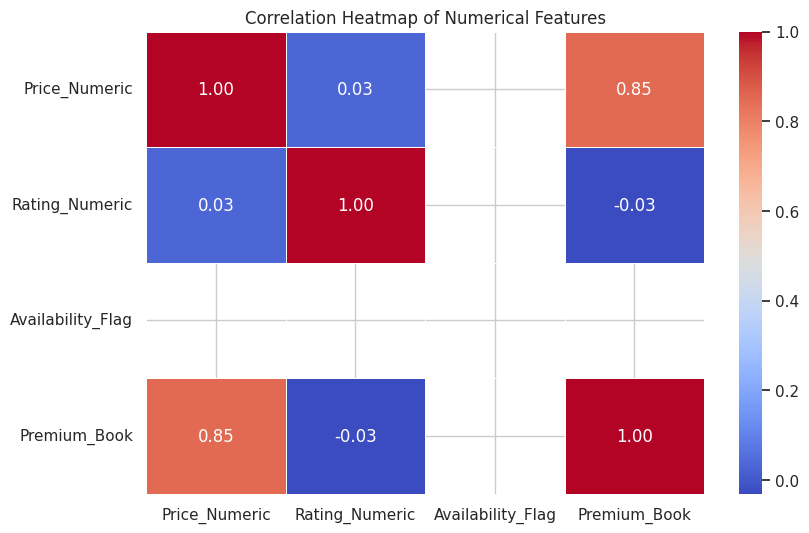

In [ ]:
# 4. Correlation heatmap for numerical features.

numeric_columns = [
    "Price_Numeric",
    "Rating_Numeric",
    "Availability_Flag",
    "Premium_Book"
]

correlation_matrix = clean_df[numeric_columns].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

### Explanation

A correlation heatmap summarizes linear relationships between numerical variables. Values closer to +1 indicate positive correlation, values closer to -1 indicate negative correlation, and values near 0 indicate weak linear association.

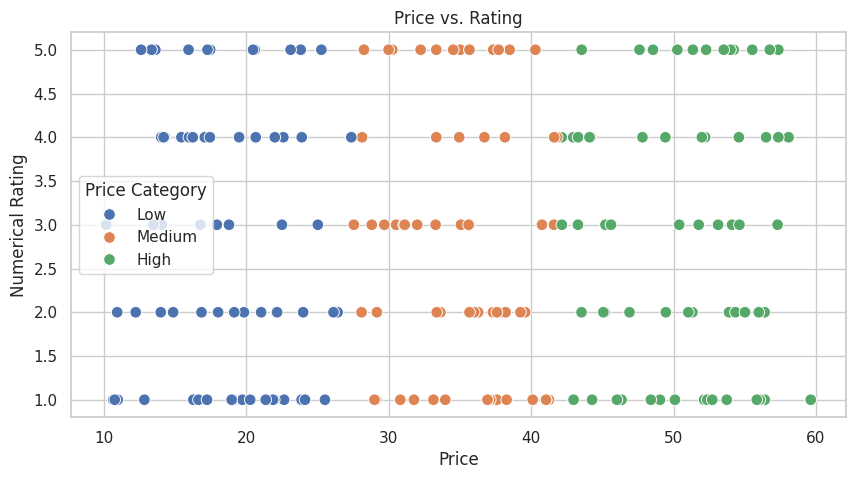

In [ ]:
# 5. Scatter plot of price against numerical rating.

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=clean_df,
    x="Price_Numeric",
    y="Rating_Numeric",
    hue="Price_Category",
    s=70
)
plt.title("Price vs. Rating")
plt.xlabel("Price")
plt.ylabel("Numerical Rating")
plt.legend(title="Price Category")
plt.show()

### Explanation

The scatter plot shows individual books according to price and rating. The different price categories make it easier to observe whether groups occupy different regions of the plot.

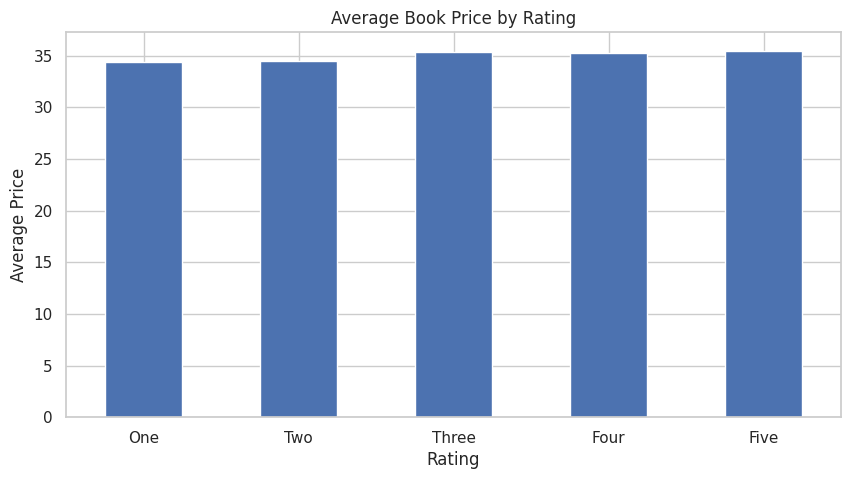

In [ ]:
# 6. Bar chart showing average price by rating.

average_price_by_rating = (
    clean_df.groupby("Rating", observed=True)["Price_Numeric"]
    .mean()
    .reindex(["One", "Two", "Three", "Four", "Five"])
)

plt.figure(figsize=(10, 5))
average_price_by_rating.plot(kind="bar")
plt.title("Average Book Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Average Price")
plt.xticks(rotation=0)
plt.show()

### Explanation

The bar chart compares average book prices across rating groups. It provides an easy-to-read summary of whether higher or lower rated books tend to have different average prices in this scraped sample.

# SECTION 11: Machine Learning

A simple **Random Forest Classifier** is used to predict the numerical rating class.

## Machine-Learning Workflow

1. Select useful features.
2. Define the target variable.
3. Split data into training and testing sets.
4. Train the Random Forest model.
5. Generate predictions.
6. Evaluate accuracy.
7. Display a confusion matrix.
8. Display a classification report.

### Important modeling decision

The target is `Rating_Numeric`. The rating itself is **not** included among the input features, because doing so would cause target leakage. Instead, the model uses:
- Price
- Availability Flag
- Premium Book Indicator
- Encoded Category

In [ ]:
# Prepare the machine-learning dataset.

ml_df = clean_df.copy()

# Convert the categorical Category feature to numerical codes.
# This is used only for the ML model; the original Category text is retained.
ml_df["Category_Code"] = ml_df["Category"].astype("category").cat.codes

# Select input features.
feature_columns = [
    "Price_Numeric",
    "Availability_Flag",
    "Premium_Book",
    "Category_Code"
]

X = ml_df[feature_columns]
y = ml_df["Rating_Numeric"]

print("Input features:")
display(X.head())

print("Target values:")
display(y.head())

Input features:


,Price_Numeric,Availability_Flag,Premium_Book,Category_Code
0,51.77,1,1,7
1,53.74,1,1,3
2,50.1,1,1,2
3,47.82,1,1,6
4,54.23,1,1,4


Target values:


,Rating_Numeric
0,3
1,1
2,1
3,4
4,5


### Explanation

The input matrix `X` contains only information that would be available without knowing the book's rating. The target vector `y` contains the rating class that the model must predict.

In [ ]:
# Split the data into training and testing subsets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 160
Testing samples: 40


### Explanation

An 80:20 train-test split is used. Stratification attempts to preserve the relative distribution of rating classes in both sets. The test set is kept separate so that the model can be evaluated on unseen observations.

In [ ]:
# Train the Random Forest classifier.

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

random_forest.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


### Explanation

Random Forest combines many decision trees and aggregates their predictions. It can capture non-linear relationships and is suitable for a simple tabular classification task.

In [ ]:
# Generate predictions on the unseen test set.

y_pred = random_forest.predict(X_test)

# Calculate classification accuracy.
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print("Accuracy (%):", round(accuracy * 100, 2))

Accuracy: 0.25
Accuracy (%): 25.0


### Explanation

Accuracy represents the proportion of test observations classified correctly. Because this is a multi-class problem, accuracy should be interpreted together with the confusion matrix and classification report.

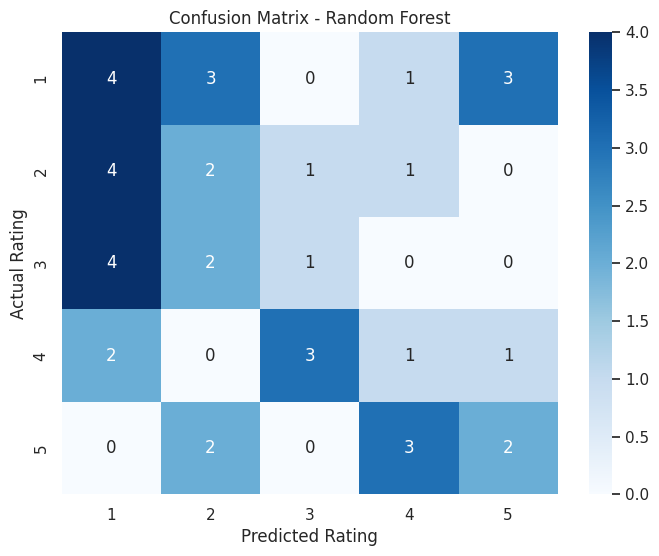

In [ ]:
# Create and display the confusion matrix.

cm = confusion_matrix(y_test, y_pred, labels=[1, 2, 3, 4, 5])

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[1, 2, 3, 4, 5],
    yticklabels=[1, 2, 3, 4, 5]
)
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted Rating")
plt.ylabel("Actual Rating")
plt.show()

### Explanation

The confusion matrix shows actual classes against predicted classes. Diagonal values represent correct predictions, while off-diagonal values represent misclassifications.

In [ ]:
# Display the classification report.

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[1, 2, 3, 4, 5],
        target_names=["One", "Two", "Three", "Four", "Five"],
        zero_division=0
    )
)

Classification Report:
              precision    recall  f1-score   support

         One       0.29      0.36      0.32        11
         Two       0.22      0.25      0.24         8
       Three       0.20      0.14      0.17         7
        Four       0.17      0.14      0.15         7
        Five       0.33      0.29      0.31         7

    accuracy                           0.25        40
   macro avg       0.24      0.24      0.24        40
weighted avg       0.25      0.25      0.24        40



### Explanation

The classification report provides:
- **Precision:** how many predicted members of a class were actually correct.
- **Recall:** how many actual members of a class were correctly found.
- **F1-score:** harmonic mean of precision and recall.
- **Support:** number of actual test samples in each class.

The results depend on the web-scraped sample and should not be interpreted as a general model of all books.

,Feature,Importance
0,Price_Numeric,0.918500
3,Category_Code,0.070215
2,Premium_Book,0.011285
1,Availability_Flag,0.000000


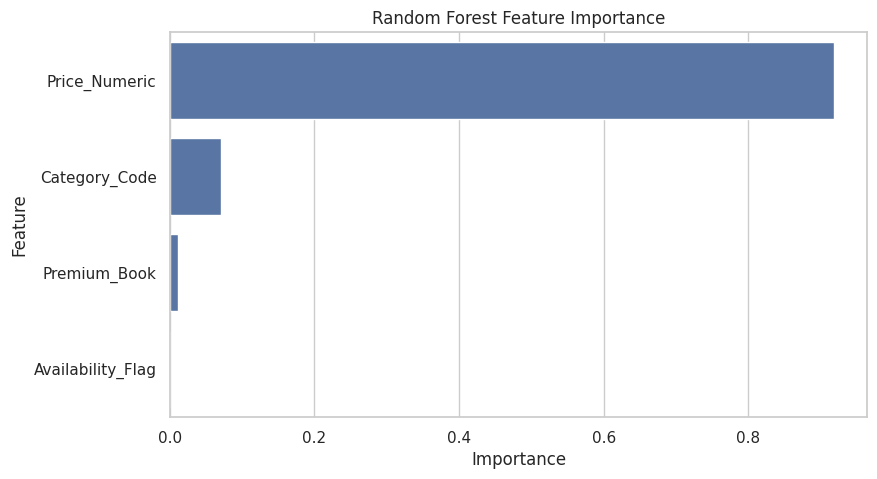

In [ ]:
# Display Random Forest feature importance.

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": random_forest.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Explanation

Feature importance indicates how useful each input variable was for the trained Random Forest. It should be interpreted as model-specific importance rather than proof of causation.

# SECTION 12: Final Dataset

The final dataset contains:
- Original cleaned fields
- Numerical rating
- Numerical price
- Price category
- Availability flag
- Premium book indicator
- Category code for machine-learning use

The final file is saved as `cleaned_dataset.csv`.

In [ ]:
# Arrange the final dataset into a clean, readable column order.

final_columns = [
    "Book_Title",
    "Price",
    "Price_Numeric",
    "Rating",
    "Rating_Numeric",
    "Availability_Status",
    "Availability_Flag",
    "Category",
    "Category_Code",
    "Price_Category",
    "Premium_Book"
]

final_df = ml_df[final_columns].copy()

# Save the final cleaned and feature-engineered dataset.
final_df.to_csv("cleaned_dataset.csv", index=False)

# Display the final dataset.
display(final_df.head(10))

print("Final dataset shape:", final_df.shape)
print("Final dataset saved as: cleaned_dataset.csv")

,Book_Title,Price,Price_Numeric,Rating,Rating_Numeric,Availability_Status,Availability_Flag,Category,Category_Code,Price_Category,Premium_Book
0,A Light in the Attic,Â£51.77,51.77,Three,3,In stock,1,Poetry,7,High,1
1,Tipping the Velvet,Â£53.74,53.74,One,1,In stock,1,Historical Fiction,3,High,1
2,Soumission,Â£50.10,50.1,One,1,In stock,1,Fiction,2,High,1
3,Sharp Objects,Â£47.82,47.82,Four,4,In stock,1,Mystery,6,High,1
4,Sapiens: A Brief History of Humankind,Â£54.23,54.23,Five,5,In stock,1,History,4,High,1
5,The Requiem Red,Â£22.65,22.65,One,1,In stock,1,Young Adult,13,Low,0
6,The Dirty Little Secrets of Getting Your Dream...,Â£33.34,33.34,Four,4,In stock,1,Business,0,Medium,0
7,The Coming Woman: A Novel Based on the Life of...,Â£17.93,17.93,Three,3,In stock,1,Default,1,Low,0
8,The Boys in the Boat: Nine Americans and Their...,Â£22.60,22.6,Four,4,In stock,1,Default,1,Low,0
9,The Black Maria,Â£52.15,52.15,One,1,In stock,1,Poetry,7,High,1


Final dataset shape: (200, 11)
Final dataset saved as: cleaned_dataset.csv


### Explanation

The final dataset combines cleaned raw information and engineered features. Saving this file makes the result reusable for future analysis and machine-learning experiments.

In [ ]:
# Final verification checklist.

print("========== FINAL DATASET VERIFICATION ==========")
print("Rows:", final_df.shape[0])
print("Columns:", final_df.shape[1])
print("Missing values:", int(final_df.isnull().sum().sum()))
print("Duplicate rows:", int(final_df.duplicated().sum()))
print("Price data type:", final_df["Price_Numeric"].dtype)
print("Rating data type:", final_df["Rating_Numeric"].dtype)

print("\nFinal columns:")
for column in final_df.columns:
    print("-", column)

# Show a statistical summary of important numerical features.
display(
    final_df[
        ["Price_Numeric", "Rating_Numeric", "Availability_Flag", "Premium_Book"]
    ].describe().round(3)
)

========== FINAL DATASET VERIFICATION ==========
Rows: 200
Columns: 11
Missing values: 4
Duplicate rows: 0
Price data type: Float64
Rating data type: int64

Final columns:
- Book_Title
- Price
- Price_Numeric
- Rating
- Rating_Numeric
- Availability_Status
- Availability_Flag
- Category
- Category_Code
- Price_Category
- Premium_Book


,Price_Numeric,Rating_Numeric,Availability_Flag,Premium_Book
count,200.0,200.000,200.0,200.000
mean,34.92,2.810,1.0,0.490
std,13.912,1.464,0.0,0.501
min,10.16,1.000,1.0,0.000
25%,22.148,1.000,1.0,0.000
50%,35.67,3.000,1.0,0.000
75%,45.715,4.000,1.0,1.000
max,59.64,5.000,1.0,1.000


In [ ]:
# Download the final cleaned dataset to your computer.

from google.colab import files

files.download("cleaned_dataset.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Explanation

The final verification confirms that the dataset contains the expected number of records, no remaining missing values or duplicate rows, and appropriate numerical data types for the engineered numerical features.

# SECTION 13: Conclusion

This project demonstrated a complete data-science workflow starting from raw web data and ending with a machine-learning model.

### Web Scraping

The dataset was created directly from the publicly accessible **Books to Scrape** website using Requests and BeautifulSoup. At least 200 book records were collected, including title, price, rating, availability, and category. The raw dataset was preserved in CSV format.

### Data Cleaning

Exploratory analysis identified the structure and potential quality problems in the data. Realistic missing values, duplicate rows, and artificial outliers were introduced to demonstrate a practical preprocessing workflow. Missing values were handled using mean, median, and mode concepts, with median used for price and mode used for categorical variables. Duplicate rows were removed, strings were cleaned, and prices were converted from currency text into numerical values.

### Feature Engineering

The rating labels `One` to `Five` were converted into numerical values. Additional features such as `Price_Category`, `Availability_Flag`, and `Premium_Book` were created. These features demonstrate how raw website information can be transformed into variables that are easier to analyze and use in machine learning.

### Outlier Treatment

The IQR method was used to identify extreme price values. Boxplots were used before and after treatment, and IQR capping was applied to reduce the influence of outliers without unnecessarily deleting book records.

### Feature Scaling

Standardization and Min-Max Normalization were demonstrated. Standardization centers the values around zero, while Min-Max scaling maps the values to the range from 0 to 1.

### Visualization

Histograms, boxplots, count plots, correlation heatmaps, scatter plots, and bar charts were created using Matplotlib and Seaborn. These visualizations helped understand distributions, class frequencies, relationships, and trends in the processed data.

### Machine Learning

A Random Forest classifier was trained to predict book rating classes using price, availability, premium-book status, and encoded category. Accuracy, confusion matrix, classification report, and feature importance were used for evaluation.

### Key Learnings

The project demonstrates that machine learning is not only about selecting an algorithm. The quality of the input data is equally important. A complete workflow involves collecting data, understanding it, cleaning it, engineering useful features, treating outliers, scaling numerical variables when appropriate, visualizing patterns, and finally training and evaluating a model.

> **Final takeaway:** Effective data preprocessing and feature engineering transform raw web-scraped information into a structured dataset suitable for meaningful analysis and machine-learning applications.